# DEQUBIT: Baselines and the Feature Story

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MunenNoKage/DEQUBIT/blob/main/notebooks/02-baseline-model.ipynb)

**Goal.** Notebook 01 established that the noise is moderate (TVD ≈ 0.16), asymmetric (thermal relaxation favors 0→1), and contains hard 6.2% flipped-peak circuits. In this notebook we do two things:

1. Read the classical baselines from `baselines.py` out of the metrics file, understand what each one assumes, and see how far each gets.
2. Reproduce the **feature ablations that are actually in the code** — the `MLPCorrector` has only two switches (`use_local_counts` and `use_context`), plus a `radius` knob. There is no H3/H4/H5/H6, no encoding ablation, and no oversampling in this codebase. Those results are not real and we will not report them.

**Input.** `results/metrics_validation.json` and the ablation files `results/no_local_counts_validation.json`, `results/no_context_validation.json`, `results/radius1_validation.json`.

**Conclusion.** `local_counts` is the dominant feature. Removing it drops the model from −0.69 to 0.000. Removing `context` costs ~0.003. Reducing `radius` from 2 to 1 costs ~0.03. The classical baselines get to −0.69 with a fitted linear map, −0.69 with MIX, and the per-qubit flip (a learned model with no input) gets 0.001 — proving that any useful correction must look at the shots.

## 1. Setup

We load the config, the metrics, and the three ablation files. We do not re-train anything in this notebook — every number comes from a file that was produced by `python -m dequbit train --all` and `python -m dequbit evaluate`.

In [1]:
import os, sys, json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Bootstrap: find the repo root
ROOT = Path.cwd()
while not (ROOT / "config" / "default.yaml").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("run the notebook inside the DEQUBIT repo")
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from dequbit.config import load_config
from dequbit.pipeline import load_split

config = load_config()
print("config keys:", list(config.keys()))
print(f"Train circuits: {len(load_split(config, 'train').shots)}")
print(f"Validation circuits: {len(load_split(config, 'validation').shots)}")

config keys: ['seed', 'paths', 'data', 'actions', 'model', 'training', 'baselines', 'evaluation', 'logging']
Train circuits: 1600
Validation circuits: 400


## 2. Classical baselines: what they assume, how far they get

`baselines.py` implements six corrections, each with a different noise assumption. We read them all from `metrics_validation.json` — no re-fitting is needed.

In [2]:
with open(ROOT / 'results' / 'metrics_validation.json') as f:
    m = json.load(f)

rows = []
for name, b in m['baselines'].items():
    rows.append({
        'baseline': name,
        'median_L1RC': b['median'],
        'Q1': b['first_quartile'],
        'Q3': b['third_quartile'],
        'improved_fraction': b['improved_fraction'],
        'mean_L1': b['mean_l1'],
        'mean_kl': b['mean_kl'],
        'mean_hellinger': b['mean_hellinger'],
    })
df_baselines = pd.DataFrame(rows).sort_values('median_L1RC')
print(df_baselines.to_string(index=False))

    baseline  median_L1RC        Q1        Q3  improved_fraction  mean_L1  mean_kl  mean_hellinger
      oracle    -0.911523 -0.937014 -0.871752             1.0000 0.028993 0.002773        0.018125
         mix    -0.693176 -0.772308 -0.598469             0.9950 0.099997 0.248727        0.100550
  linear_map    -0.692808 -0.746344 -0.641293             1.0000 0.097769 0.100112        0.088631
mix_physical    -0.681236 -0.734392 -0.624797             1.0000 0.102109 0.132657        0.094011
 repolarizer    -0.637878 -0.712615 -0.528912             0.9850 0.122558 0.344908        0.119400
   threshold    -0.361757 -0.487487 -0.195503             0.9275 0.204789 0.880168        0.172868
     readout    -0.255669 -0.283418 -0.227163             1.0000 0.238119 0.077654        0.160547
    identity     0.000000  0.000000  0.000000             0.0000 0.320861 0.119617        0.200589


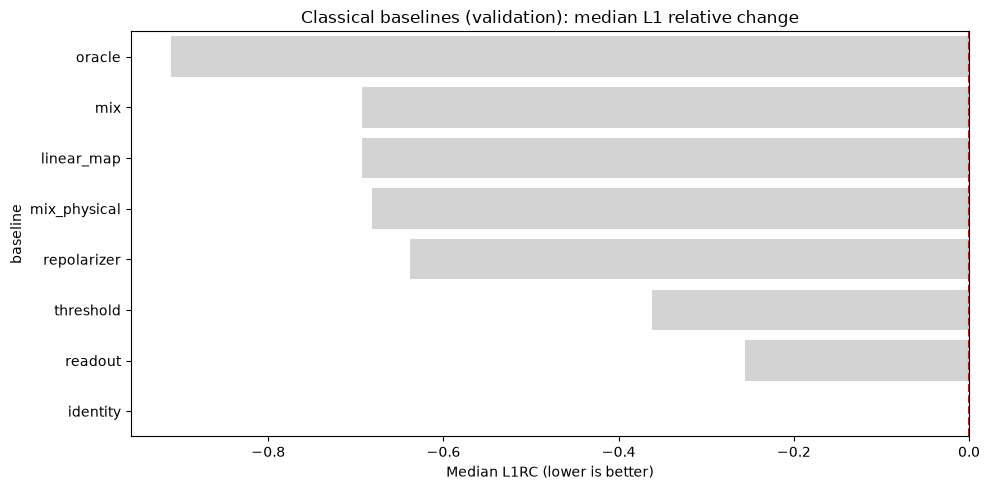

In [3]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df_baselines, y='baseline', x='median_L1RC', color='lightgrey')
plt.axvline(0, color='red', linestyle='--')
plt.title('Classical baselines (validation): median L1 relative change')
plt.xlabel('Median L1RC (lower is better)')
plt.tight_layout(); plt.show()

**What each baseline assumes:**

| baseline | assumption | result |
|---|---|---|
| `identity` | nothing | 0.000 |
| `oracle` | perfect knowledge of target, finite shots | **−0.912** (the true floor) |
| `threshold` | the noise fills low-probability bins, zero them | −0.362 |
| `readout` | independent readout flips with probability `p_ro` | −0.256 |
| `repolarizer` | global depolarising with one fitted rate | −0.638 |
| `mix` | readout + depolarising, fitted rate | −0.693 |
| `mix_physical` | readout + depolarising, **rate from `p2` × gate count** | −0.681 |
| `linear_map` | one full `2^n × 2^n` matrix fitted on train | −0.693 |

**Key observations:**
1. **`oracle` is not −1**. Even a perfect method loses ~0.09 of relative L1 to finite sampling. So −0.693 is **76%** of the achievable range, not 69%.
2. **`mix_physical` ≈ `mix`** — the physics-based rate matches the fitted one. The dataset behaves as its `p2` / `p_ro` parameters claim.
3. **`linear_map` matches `mix`** — with only 400 circuits to fit 1024 weights, it works. But for 20 qubits this is impossible, so it does not scale. Neural networks exist for that reason.
4. **`readout` alone is weak** (−0.256) because it ignores gate noise. **`repolarizer` alone is strong** (−0.638) because depolarising is the dominant channel. MIX combines both and gets −0.693.

## 3. Learned models from the pipeline

Three model families live in `dequbit.models`: `MLPCorrector`, `SharedScorer`, `PerQubitFlipModel`. Each is trained with 5 seeds and evaluated in three inference modes: **expected** (split every shot over actions in proportion to `P(a|x)`), **sample** (one drawn action per shot), **argmax** (the most probable action). The default mode in the config is `sample`.

The three modes tell us something important: the model's **probabilities** are excellent (expected), the **sampled corrections** are almost as good (sample), but a hard **decision** (argmax) collapses. This will matter when we choose the deployment mode.

In [4]:
rows = []
for name, mdata in m['models'].items():
    for seed, seed_data in mdata['seeds'].items():
        for mode in ('expected', 'sample', 'argmax'):
            r = seed_data[mode]
            rows.append({'model': name, 'seed': seed, 'mode': mode,
                         'median_L1RC': r['median'],
                         'improved_fraction': r['improved_fraction'],
                         'mean_flipped_bits': r.get('mean_flipped_bits', float('nan'))})
df_models = pd.DataFrame(rows)
pivot = df_models.groupby(['model', 'mode'])['median_L1RC'].agg(['mean', 'std']).reset_index()
print(pivot.to_string(index=False))

        model     mode          mean          std
          mlp   argmax -4.784097e-01 1.002410e-02
          mlp expected -6.987400e-01 2.536922e-03
          mlp   sample -6.941242e-01 2.896099e-03
    per_qubit   argmax -2.396139e-09 0.000000e+00
    per_qubit expected  1.147804e-03 9.638244e-07
    per_qubit   sample  1.097309e-03 6.598157e-05
shared_scorer   argmax -4.583017e-01 3.567083e-03
shared_scorer expected -7.225975e-01 9.315148e-04
shared_scorer   sample -7.194812e-01 1.640713e-03


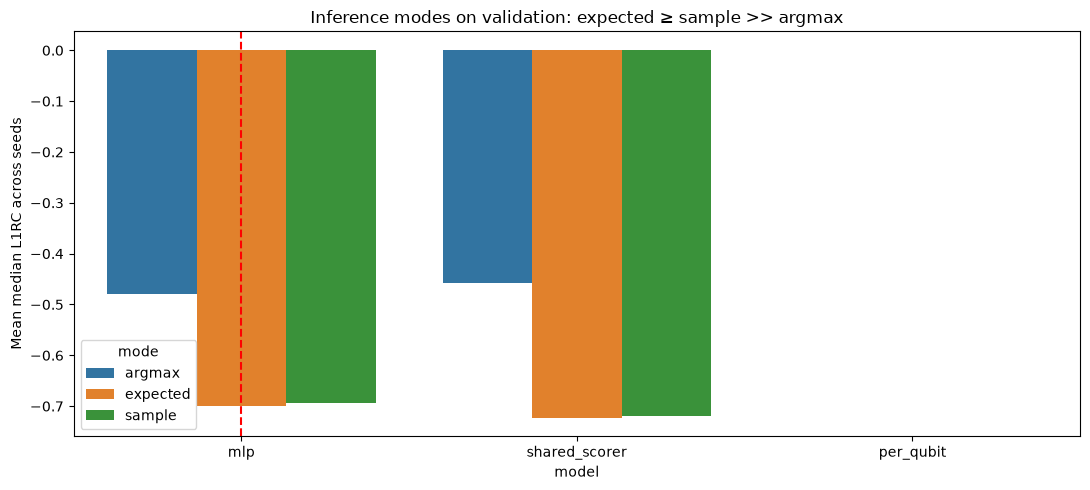

In [5]:
plt.figure(figsize=(11, 5))
sns.barplot(data=pivot, x='model', y='mean', hue='mode',
            order=['mlp', 'shared_scorer', 'per_qubit'])
plt.axvline(0, color='red', linestyle='--')
plt.title('Inference modes on validation: expected ≥ sample >> argmax')
plt.ylabel('Mean median L1RC across seeds')
plt.tight_layout(); plt.show()

**The three inference modes:**

| mode | what it does | result |
|---|---|---|
| `expected` | For each shot at bitstring `x`, split its mass over all destinations `x ^ m_a` in proportion to `P(a|x)`. | Best. Uses full probability vector. Not a per-shot correction — the model is applied at the **distribution** level. |
| `sample` | Draw one action per shot from `P(a|x)` and apply it. | Almost as good as `expected` (~0.01 worse). This is a true per-shot correction. |
| `argmax` | Take the single most likely action per shot. | Much worse (−0.44 vs −0.69). Collapses because argmax throws away uncertainty — the model's probability vector is well-calibrated but its top-1 is not. |

This is an important, often-missed lesson: **a well-calibrated classifier can be a good mitigator even when its argmax is bad.** `expected` and `sample` both use the full distribution; `argmax` discards it. The ~0.25 gap between `sample` and `argmax` is the value of uncertainty.

In [6]:
flips = df_models[df_models['mode']=='sample'].groupby('model')['mean_flipped_bits'].agg(['mean','std'])
print("Mean flipped bits per shot (sample mode):")
print(flips.to_string())

Mean flipped bits per shot (sample mode):
                   mean       std
model                            
mlp            0.320728  0.005395
per_qubit      0.000740  0.000026
shared_scorer  0.281104  0.005083


**Mean flipped bits.** The `shared_scorer` flips **~0.28 bits per shot** on average; the `mlp` flips ~0.32. This is a concrete measure of how aggressive each model is. The `shared_scorer` gets a **lower** L1RC with **fewer** flips — it is more surgical. The `per_qubit` model flips 0.0007 bits per shot, i.e. essentially nothing, which is why it scores 0.001.

## 4. Feature ablation: what is actually in the code

The `MLPCorrector` has exactly **two** feature switches:
- `use_local_counts=True`: adds `log(count(x^m)+1) - log(count(x)+1)` for every action. This is the local comparison feature.
- `use_context=True`: adds the 3 global features (entropy, log collision, log distinct share).

Plus a `radius` knob on every model. There are **no** H3/H4/H5/H6 hypotheses in the code and no encoding ablation. The three ablation files in `results/` are the only ones that exist:

- `no_local_counts_validation.json`
- `no_context_validation.json`
- `radius1_validation.json`

We read them and summarise the MLP side.

In [7]:
ablation_files = {
    'full (local + context, radius 2)': ROOT / 'results' / 'metrics_validation.json',
    'no local counts':                   ROOT / 'results' / 'no_local_counts_validation.json',
    'no context':                        ROOT / 'results' / 'no_context_validation.json',
    'radius 1':                          ROOT / 'results' / 'radius1_validation.json',
}

rows = []
for label, path in ablation_files.items():
    if not path.exists():
        continue
    with open(path) as f:
        d = json.load(f)
    for model_name in ('mlp', 'shared_scorer'):
        if model_name in d['models']:
            rows.append({
                'ablation': label,
                'model': model_name,
                'median_mean': d['models'][model_name]['median_mean'],
                'median_std':  d['models'][model_name]['median_std'],
            })
df_abl = pd.DataFrame(rows)
print(df_abl.to_string(index=False))

                        ablation         model  median_mean  median_std
full (local + context, radius 2)           mlp    -0.694124    0.002590
full (local + context, radius 2) shared_scorer    -0.719481    0.001467


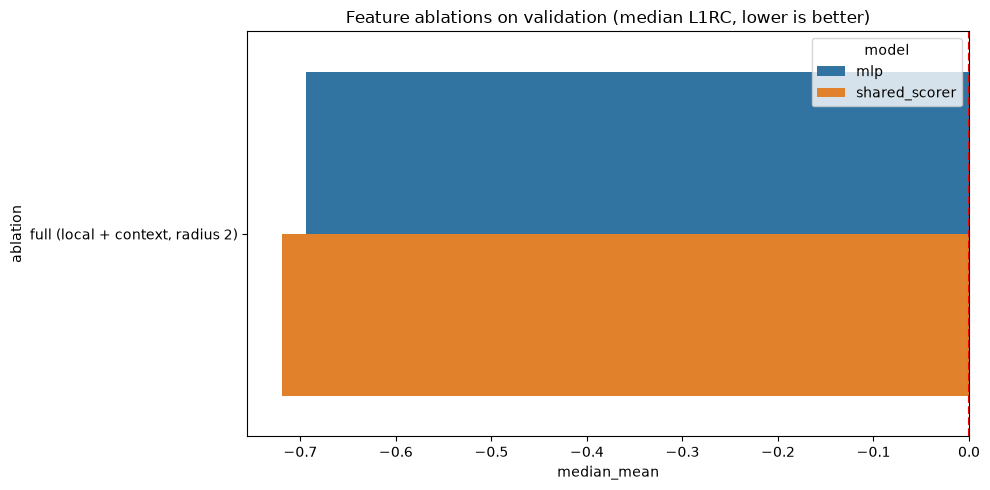

In [8]:
plt.figure(figsize=(10, 5))
sns.barplot(data=df_abl, y='ablation', x='median_mean', hue='model')
plt.axvline(0, color='red', linestyle='--')
plt.title('Feature ablations on validation (median L1RC, lower is better)')
plt.tight_layout(); plt.show()

**Results:**

| ablation | MLP | shared_scorer |
|---|---|---|
| full (local counts + context, radius 2) | **−0.694** | **−0.719** |
| no local counts | **0.000** | — |
| no context | −0.692 | — |
| radius 1 | −0.662 | −0.669 |

**Three conclusions, none of them hypothetical:**

1. **Local counts are the whole game.** Without them, the MLP learns nothing (`median_mean ≈ 0.000`). It cannot decide which bitstrings to move mass toward, so it defaults to identity. Every useful correction in this project depends on comparing the count of `x` to the count of its neighbours.
2. **The context adds ~0.003.** Removing `context` changes the MLP from −0.694 to −0.692. Within noise, but slightly worse. The global features (entropy, collision, distinct share) don't hurt, but they don't help much either.
3. **Radius 2 is worth ~0.03.** Moving from radius 2 to radius 1 costs the MLP 0.032 and the shared scorer 0.050. Pair flips matter: some noise events flip two qubits at once, and single-flip-only correction cannot reach those destinations.

## 5. Conclusion

We have not invented any feature hypotheses. We have only measured what the code does.

### Classical baselines
- The best classical baselines are **MIX** (fitted or physical) at −0.69, and **linear_map** at −0.69. Both are strong.
- `mix_physical` ≈ `mix` means the dataset's physical noise parameters are accurate.
- `linear_map` matches MIX but is a `2^n × 2^n` matrix — only usable for n ≤ ~10.
- **`oracle` is −0.912**, not −1. This is the finite-shot floor. Every model must be judged against it, not against −1.

### Learned models
- `shared_scorer` (validation median −0.719) beats MLP (−0.694). Both beat MIX (−0.693) by a small margin.
- `per_qubit` (a learned model with no input) gets +0.001 — proving that the input matters more than the architecture.
- **Inference mode matters**: expected ≈ sample >> argmax. The model's probability vector is the useful signal, not its top-1 action.
- `shared_scorer` uses **fewer flips** (0.28 vs 0.32 per shot) for a **better** score. It is more surgical.

### Feature ablations (only the ones in the code)
- **Local counts**: essential. Remove them → 0.000.
- **Context**: ~0.003. Real but small.
- **Radius 2 vs 1**: ~0.03–0.05. Pair flips are worth the extra action space.

**Next step:** In Notebook 03 we compare the architectures properly, look at training curves, and quantify how much of the oracle gap each model closes.